   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY
(200, 6)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB
None
              Age     Na_to_K
count  200.000000  200.000000
mean    44.315000   16.084485
std     16.544315    7.223956
min     15.000000    6.269000
25%     31.000000   10.445500
50%     45.000000   13.936500
75%    

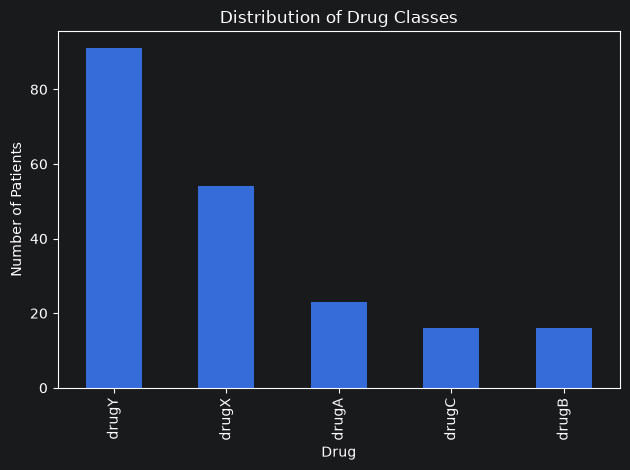

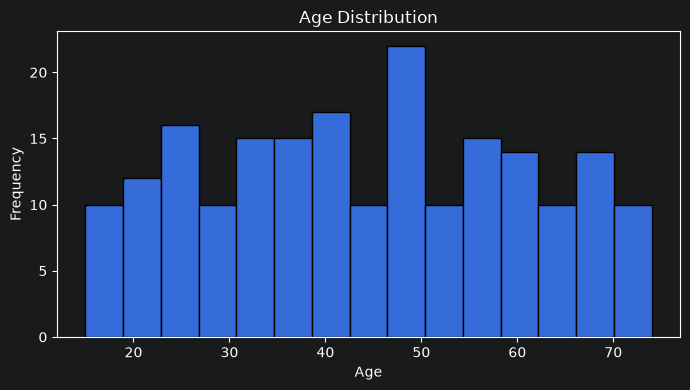


 Sex
Sex
M    104
F     96
Name: count, dtype: int64


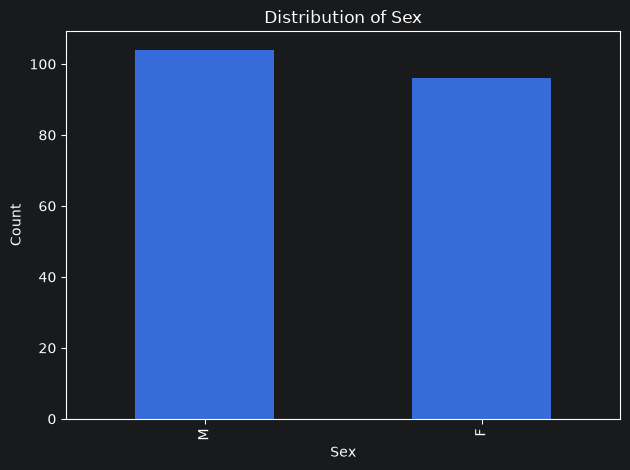


 BP
BP
HIGH      77
LOW       64
NORMAL    59
Name: count, dtype: int64


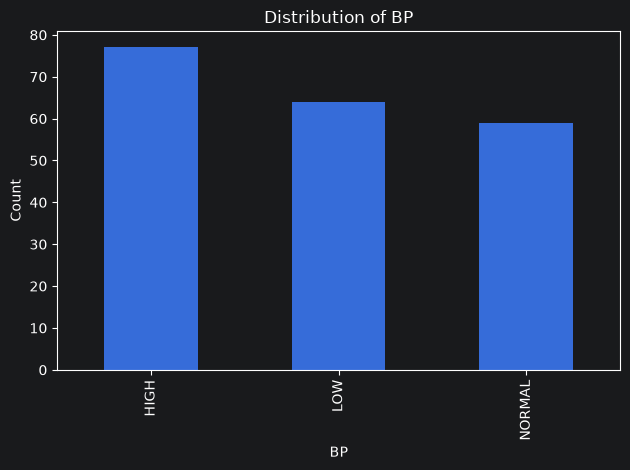


 Cholesterol
Cholesterol
HIGH      103
NORMAL     97
Name: count, dtype: int64


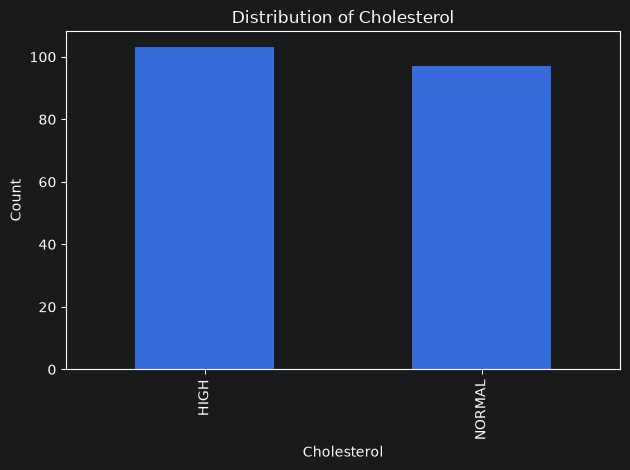

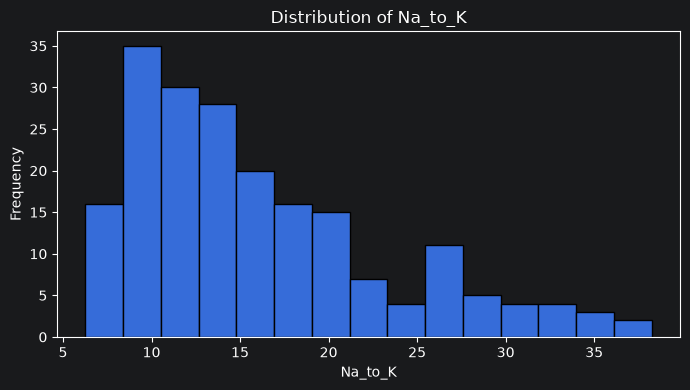


Drug distribution by Sex
Drug  drugA  drugB  drugC  drugX  drugY
Sex                                    
F         9      6      7     27     47
M        14     10      9     27     44

Drug distribution by BP
Drug    drugA  drugB  drugC  drugX  drugY
BP                                       
HIGH       23     16      0      0     38
LOW         0      0     16     18     30
NORMAL      0      0      0     36     23

Drug distribution by Cholesterol
Drug         drugA  drugB  drugC  drugX  drugY
Cholesterol                                   
HIGH            12      8     16     20     47
NORMAL          11      8      0     34     44


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("drug200.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Distribution of the target variable
print(df["Drug"].value_counts())

df["Drug"].value_counts().plot(kind="bar")
plt.title("Distribution of Drug Classes")
plt.xlabel("Drug")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

# Distribution of age
plt.figure(figsize=(7, 4))
plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Explore categorical variables
for column in ["Sex", "BP", "Cholesterol"]:
    print("\n", column)
    print(df[column].value_counts())

    df[column].value_counts().plot(kind="bar")
    plt.title("Distribution of " + column)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# Explore Na_to_K
plt.figure(figsize=(7, 4))
plt.hist(df["Na_to_K"], bins=15, edgecolor="black")
plt.title("Distribution of Na_to_K")
plt.xlabel("Na_to_K")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Explore target against categorical features
for column in ["Sex", "BP", "Cholesterol"]:
    print("\nDrug distribution by", column)
    print(pd.crosstab(df[column], df["Drug"]))

In [20]:
X = df.drop("Drug", axis=1)
y = df["Drug"]

print("Input features:", X.columns.tolist())
print("Target classes:", y.unique())

Input features: ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K']
Target classes: <StringArray>
['drugY', 'drugC', 'drugX', 'drugA', 'drugB']
Length: 5, dtype: str


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 40


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

categorical_features = ["Sex", "BP", "Cholesterol"]
numerical_features = ["Age", "Na_to_K"]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("num", "passthrough", numerical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed.")
y_pred = model.predict(X_test)
print("Actual values:")
print(y_test.values[:])

print("Predicted values:")
print(y_pred[:])

Model training completed.
Actual values:
<StringArray>
['drugC', 'drugX', 'drugA', 'drugX', 'drugY', 'drugY', 'drugY', 'drugY',
 'drugY', 'drugY', 'drugA', 'drugY', 'drugC', 'drugY', 'drugX', 'drugB',
 'drugC', 'drugX', 'drugY', 'drugA', 'drugX', 'drugX', 'drugX', 'drugY',
 'drugX', 'drugX', 'drugB', 'drugA', 'drugX', 'drugY', 'drugA', 'drugY',
 'drugB', 'drugX', 'drugY', 'drugY', 'drugY', 'drugY', 'drugY', 'drugY']
Length: 40, dtype: str
Predicted values:
['drugC' 'drugX' 'drugA' 'drugX' 'drugY' 'drugY' 'drugY' 'drugY' 'drugY'
 'drugY' 'drugA' 'drugY' 'drugC' 'drugY' 'drugX' 'drugB' 'drugC' 'drugX'
 'drugY' 'drugA' 'drugX' 'drugX' 'drugX' 'drugY' 'drugX' 'drugX' 'drugA'
 'drugA' 'drugX' 'drugY' 'drugA' 'drugY' 'drugB' 'drugX' 'drugY' 'drugY'
 'drugY' 'drugY' 'drugY' 'drugY']


Accuracy: 0.975

Classification Report:
              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        18

    accuracy                           0.97        40
   macro avg       0.97      0.93      0.94        40
weighted avg       0.98      0.97      0.97        40



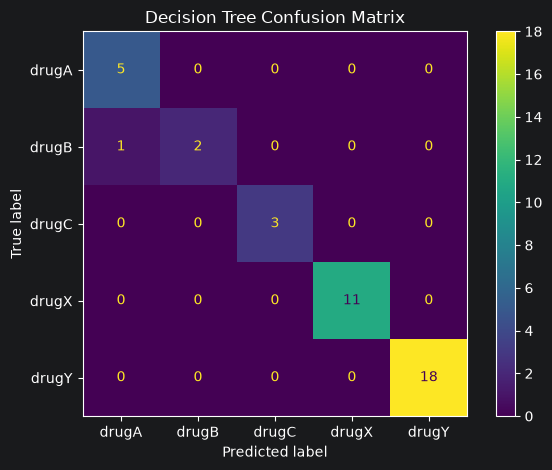

In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.named_steps["classifier"].classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.named_steps["classifier"].classes_
)

display.plot()
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

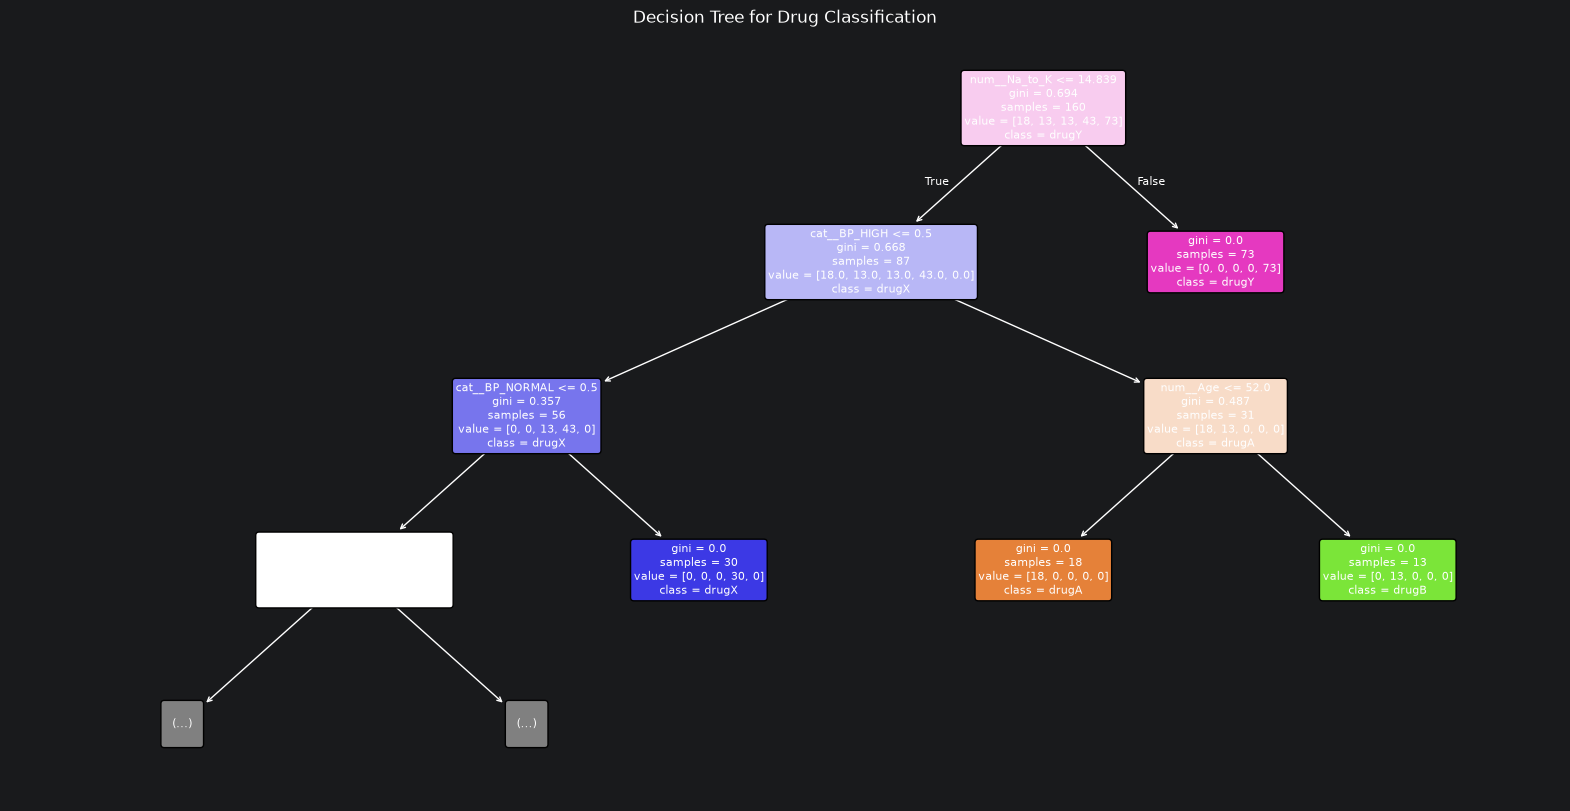

In [24]:
from sklearn.tree import plot_tree

preprocessor_fitted = model.named_steps["preprocessor"]
tree_model = model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Drug Classification")
plt.show()